# Mô phỏng NMF trên dữ liệu nhỏ

Notebook này chạy lại 8 bước của tab "Mô phỏng NMF" trong app, dùng để dự phòng khi demo app bị lỗi. Dữ liệu là 9 câu review điện thoại trong `data/mo_phong.txt`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.nmf import EPS, nmf, normalize, top_words
from src.preprocess import preprocess
from src.summarizer import grs_scores, select_grs, select_topic
from src.vectorize import build_matrix

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

k = 3
seed = 0          # đổi thành 49 để thấy trường hợp NMF gộp chủ đề
max_iter = 200
method = "topic"  # hoặc "grs"
n_sent = 3

## Bước 1. Tách câu

In [2]:
text = open("data/mo_phong.txt", encoding="utf-8").read()
# trang mô phỏng không loại câu ngắn
sentences = preprocess(text, min_syllables=0)
names = [f"S{i + 1}" for i in range(len(sentences))]
for name, s in zip(names, sentences):
    print(name, s["original"])

S1 Điện thoại mới có thời lượng pin rất tốt, dùng cả ngày vẫn còn pin.
S2 Camera chụp ảnh ban ngày đẹp, màu sắc tự nhiên.
S3 Giá bán của máy khá cao so với các đối thủ cùng phân khúc.
S4 Pin được sạc nhanh, chỉ khoảng ba mươi phút là đầy.
S5 Camera chụp đêm hơi mờ và nhiễu.
S6 Nhiều người cho rằng mức giá này chưa hợp lý.
S7 Sau một tuần sử dụng, pin vẫn trâu và máy không bị nóng.
S8 Chế độ chụp chân dung của camera xóa phông khá đẹp.
S9 Nếu giá rẻ hơn, máy sẽ rất đáng mua.


## Bước 2. Tiền xử lý

Tách từ, chữ thường, bỏ dấu câu, số và stopword.

In [3]:
for name, s in zip(names, sentences):
    print(name, "|", s["tokenized"])
    print("   ->", " ".join(s["words"]))

S1 | Điện_thoại mới có thời_lượng pin rất tốt , dùng cả ngày vẫn còn pin .
   -> điện_thoại thời_lượng pin pin
S2 | Camera chụp ảnh ban_ngày đẹp , màu_sắc tự_nhiên .
   -> camera chụp ảnh ban_ngày đẹp màu_sắc tự_nhiên
S3 | Giá bán của máy khá cao so với các đối_thủ cùng phân_khúc .
   -> giá máy đối_thủ phân_khúc
S4 | Pin được sạc nhanh , chỉ khoảng ba mươi phút là đầy .
   -> pin sạc mươi phút
S5 | Camera chụp đêm hơi mờ và nhiễu .
   -> camera chụp đêm hơi mờ nhiễu
S6 | Nhiều người cho rằng mức giá này chưa hợp_lý .
   -> giá hợp_lý
S7 | Sau một tuần sử_dụng , pin vẫn trâu và máy không bị nóng .
   -> tuần pin trâu máy nóng
S8 | Chế_độ chụp chân_dung của camera xóa_phông khá đẹp .
   -> chế_độ chụp chân_dung camera xóa_phông đẹp
S9 | Nếu giá rẻ hơn , máy sẽ rất đáng mua .
   -> giá rẻ máy mua


## Bước 3. Ma trận đếm và IDF

idf = ln((1 + n) / (1 + df)) + 1, với n là số câu và df là số câu chứa từ.

In [4]:
mat = build_matrix(sentences)
V, terms = mat["V"], mat["terms"]
cols = [names[i] for i in mat["sent_idx"]]

counts = pd.DataFrame(mat["counts"], index=terms, columns=cols)
counts["df"] = (mat["counts"] > 0).sum(axis=1)
counts["idf"] = mat["idf"].round(3)
counts

,S1,S2,S3,S4,S5,S6,S7,S8,S9,df,idf
ban_ngày,0,1,0,0,0,0,0,0,0,1,2.609
camera,0,1,0,0,1,0,0,1,0,3,1.916
chân_dung,0,0,0,0,0,0,0,1,0,1,2.609
chế_độ,0,0,0,0,0,0,0,1,0,1,2.609
chụp,0,1,0,0,1,0,0,1,0,3,1.916
giá,0,0,1,0,0,1,0,0,1,3,1.916
hơi,0,0,0,0,1,0,0,0,0,1,2.609
hợp_lý,0,0,0,0,0,1,0,0,0,1,2.609
mua,0,0,0,0,0,0,0,0,1,1,2.609
màu_sắc,0,1,0,0,0,0,0,0,0,1,2.609


## Bước 4. Ma trận V (TF-IDF)

Trước và sau khi chuẩn hóa L2 từng cột. NMF chạy trên V đã chuẩn hóa.

In [5]:
print("tf x idf:")
print(pd.DataFrame(mat["V_raw"], index=terms, columns=cols).round(3))
print()
print("V sau khi chuẩn hóa L2:")
print(pd.DataFrame(V, index=terms, columns=cols).round(3))

tf x idf:
               S1     S2     S3     S4     S5     S6     S7     S8     S9
ban_ngày    0.000  2.609  0.000  0.000  0.000  0.000  0.000  0.000  0.000
camera      0.000  1.916  0.000  0.000  1.916  0.000  0.000  1.916  0.000
chân_dung   0.000  0.000  0.000  0.000  0.000  0.000  0.000  2.609  0.000
chế_độ      0.000  0.000  0.000  0.000  0.000  0.000  0.000  2.609  0.000
chụp        0.000  1.916  0.000  0.000  1.916  0.000  0.000  1.916  0.000
giá         0.000  0.000  1.916  0.000  0.000  1.916  0.000  0.000  1.916
hơi         0.000  0.000  0.000  0.000  2.609  0.000  0.000  0.000  0.000
hợp_lý      0.000  0.000  0.000  0.000  0.000  2.609  0.000  0.000  0.000
mua         0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  2.609
màu_sắc     0.000  2.609  0.000  0.000  0.000  0.000  0.000  0.000  0.000
máy         0.000  0.000  1.916  0.000  0.000  0.000  1.916  0.000  1.916
mươi        0.000  0.000  0.000  2.609  0.000  0.000  0.000  0.000  0.000
mờ          0.000  0.000  0.

## Bước 5. Khởi tạo W, H ngẫu nhiên

In [6]:
res = nmf(V, k, max_iter=max_iter, seed=seed, save_history=True)
history, losses = res["history"], res["losses"]
n_iter = len(losses) - 1
topics = [f"Chủ đề {j + 1}" for j in range(k)]

W0, H0 = history[0]
print("Loss ban đầu:", round(losses[0], 4))
print("H ban đầu:")
print(pd.DataFrame(H0, index=topics, columns=cols).round(3))

Loss ban đầu: 2.8845
H ban đầu:
             S1     S2     S3     S4     S5     S6     S7     S8     S9
Chủ đề 1  0.141  0.147  0.002  0.131  0.149  0.146  0.023  0.148  0.135
Chủ đề 2  0.125  0.073  0.035  0.122  0.140  0.040  0.082  0.067  0.142
Chủ đề 3  0.006  0.111  0.093  0.004  0.109  0.002  0.115  0.078  0.141


## Bước 6. Lặp cập nhật W và H

H ← H × (WᵀV) / (WᵀWH), sau đó W ← W × (VHᵀ) / (WHHᵀ).

Dừng ở vòng 12 vì loss gần như không giảm nữa

H ở vòng 1:
             S1     S2     S3     S4     S5     S6     S7     S8     S9
Chủ đề 1  0.224  0.516  0.016  0.361  0.351  0.108  0.089  0.519  0.230
Chủ đề 2  0.349  0.195  0.203  0.411  0.340  0.185  0.323  0.290  0.205
Chủ đề 3  0.010  0.425  0.467  0.008  0.287  0.009  0.270  0.262  0.266

H[0,0] mới = 0.1410 x 0.0881 / 0.0554 = 0.2241


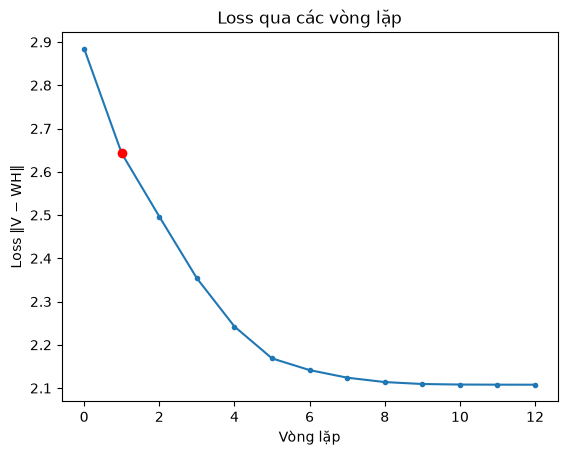

In [7]:
if n_iter < max_iter:
    print(f"Dừng ở vòng {n_iter} vì loss gần như không giảm nữa")
else:
    print(f"Dừng ở vòng {n_iter} vì đã chạy đủ số vòng lặp tối đa")

t = 1  # vòng lặp muốn xem
W_t, H_t = history[t]
print(f"\nH ở vòng {t}:")
print(pd.DataFrame(H_t, index=topics, columns=cols).round(3))

# tính tay H[0, 0] ở vòng t
i, j = 0, 0
W_old, H_old = history[t - 1]
num = (W_old.T @ V)[i, j]
den = (W_old.T @ W_old @ H_old)[i, j] + EPS
print(f"\nH[{i},{j}] mới = {H_old[i, j]:.4f} x {num:.4f} / {den:.4f} = {H_old[i, j] * num / den:.4f}")

plt.plot(losses, marker=".")
plt.plot(t, losses[t], "ro")
plt.xlabel("Vòng lặp")
plt.ylabel("Loss ‖V − WH‖")
plt.title("Loss qua các vòng lặp")
plt.show()

## Bước 7. Kết quả phân rã

Chuẩn hóa để mỗi cột W có tổng bằng 1, xếp chủ đề theo tổng hàng của H.

Chủ đề 1: chụp (0.13), camera (0.13), đẹp (0.11), chế_độ (0.07), chân_dung (0.07)
Chủ đề 2: giá (0.24), máy (0.17), hợp_lý (0.12), phân_khúc (0.11), đối_thủ (0.11)
Chủ đề 3: pin (0.27), điện_thoại (0.10), thời_lượng (0.10), phút (0.09), mươi (0.09)


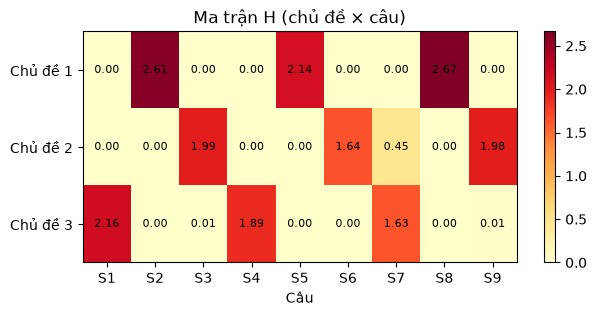

In [8]:
W, H = normalize(history[-1][0], history[-1][1])
for j, ws in enumerate(top_words(W, terms, 5)):
    print(topics[j] + ":", ", ".join(f"{w} ({W[terms.index(w), j]:.2f})" for w in ws))

fig, ax = plt.subplots(figsize=(7, 3))
im = ax.imshow(H, cmap="YlOrRd", aspect="auto")
for a in range(k):
    for b in range(len(cols)):
        ax.text(b, a, f"{H[a, b]:.2f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(cols)), cols)
ax.set_yticks(range(k), topics)
ax.set_xlabel("Câu")
ax.set_title("Ma trận H (chủ đề × câu)")
fig.colorbar(im)
plt.show()

## Bước 8. Chọn câu

In [9]:
w, score = grs_scores(H)
if method == "topic":
    chosen = select_topic(H, n_sent)
    for x, c in enumerate(chosen):
        print(f"Lượt {x + 1}: {topics[x % k]} chọn {cols[c]} (H = {H[x % k, c]:.3f})")
else:
    print("Trọng số chủ đề:", np.round(w, 3))
    chosen = select_grs(H, n_sent)

print()
for c, name in enumerate(cols):
    mark = "*" if c in chosen else " "
    print(f"{mark} {name}  GRS = {score[c]:.3f}  {sentences[mat['sent_idx'][c]]['original']}")

selected = sorted(mat["sent_idx"][c] for c in chosen)
print("\nBản tóm tắt:")
print(" ".join(sentences[s]["original"] for s in selected))

Lượt 1: Chủ đề 1 chọn S8 (H = 2.666)
Lượt 2: Chủ đề 2 chọn S3 (H = 1.986)
Lượt 3: Chủ đề 3 chọn S1 (H = 2.158)

* S1  GRS = 0.641  Điện thoại mới có thời lượng pin rất tốt, dùng cả ngày vẫn còn pin.
  S2  GRS = 1.012  Camera chụp ảnh ban ngày đẹp, màu sắc tự nhiên.
* S3  GRS = 0.630  Giá bán của máy khá cao so với các đối thủ cùng phân khúc.
  S4  GRS = 0.560  Pin được sạc nhanh, chỉ khoảng ba mươi phút là đầy.
  S5  GRS = 0.830  Camera chụp đêm hơi mờ và nhiễu.
  S6  GRS = 0.518  Nhiều người cho rằng mức giá này chưa hợp lý.
  S7  GRS = 0.625  Sau một tuần sử dụng, pin vẫn trâu và máy không bị nóng.
* S8  GRS = 1.032  Chế độ chụp chân dung của camera xóa phông khá đẹp.
  S9  GRS = 0.630  Nếu giá rẻ hơn, máy sẽ rất đáng mua.

Bản tóm tắt:
Điện thoại mới có thời lượng pin rất tốt, dùng cả ngày vẫn còn pin. Giá bán của máy khá cao so với các đối thủ cùng phân khúc. Chế độ chụp chân dung của camera xóa phông khá đẹp.
